<a href="https://colab.research.google.com/github/khanhlinh1808/balc/blob/master/BALC_loss_(full)_Mean_Teacher_pretrained_Densenet_0_3_labeled.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ===== CÀI ĐẶT THƯ VIỆN =====
!pip install segmentation-models-pytorch
!pip install albumentations
!pip install opencv-python
!pip install scikit-image
!pip install tqdm
!pip install matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 14.7 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.utils import save_image
import segmentation_models_pytorch as smp
import cv2
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import random
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Set random seeds
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

In [ ]:
!ls '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/kvasir-seg.zip'
!unzip -q '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/kvasir-seg.zip'

'/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/kvasir-seg.zip'


In [ ]:
# ===== DATASET CLASS =====
class KvasirDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None, is_labeled=True):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform
        self.is_labeled = is_labeled

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # Load image
        image = cv2.imread(self.image_paths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.is_labeled:
            # Load mask
            mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
            mask = (mask > 0).astype(np.uint8)

            if self.transform:
                augmented = self.transform(image=image, mask=mask)
                image = augmented['image']
                mask = augmented['mask']

            # Ensure mask has correct shape [H, W] -> [1, H, W]
            if len(mask.shape) == 2:
                mask = mask.unsqueeze(0)

            return image, mask.float()  # Changed to float for BCE loss
        else:
            if self.transform:
                augmented = self.transform(image=image)
                image = augmented['image']

            return image

In [ ]:
# ===== DATA AUGMENTATION =====
def get_transforms():
    train_transform = A.Compose([
        A.Resize(256, 256),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Rotate(limit=30, p=0.5),
        A.RandomBrightnessContrast(p=0.3),
        A.GaussNoise(p=0.2),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2()
    ])

    val_transform = A.Compose([
        A.Resize(256, 256),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2()
    ])

    return train_transform, val_transform

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

def sobel_edges(x):
    """Compute Sobel edge magnitude"""
    sobel_x = torch.tensor(
        [[-1, 0, 1],
         [-2, 0, 2],
         [-1, 0, 1]],
        dtype=torch.float32, device=x.device
    ).unsqueeze(0).unsqueeze(0)

    sobel_y = torch.tensor(
        [[-1, -2, -1],
         [ 0,  0,  0],
         [ 1,  2,  1]],
        dtype=torch.float32, device=x.device
    ).unsqueeze(0).unsqueeze(0)

    grad_x = F.conv2d(x, sobel_x, padding=1)
    grad_y = F.conv2d(x, sobel_y, padding=1)

    edge = torch.sqrt(grad_x ** 2 + grad_y ** 2 + 1e-8)
    return edge


class BoundaryLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, pred, target):
        pred = torch.sigmoid(pred)
        target = target.float()

        pred_edge = sobel_edges(pred)
        target_edge = sobel_edges(target)

        return F.mse_loss(pred_edge, target_edge)

class LowContrastLoss(nn.Module):
    def __init__(self, threshold=0.1):
        super().__init__()
        self.threshold = threshold

    def forward(self, pred, target):
        pred = torch.sigmoid(pred)
        target = target.float()

        target_edge = sobel_edges(target)
        contrast_mask = (target_edge < self.threshold).float()

        return F.mse_loss(pred * contrast_mask, target * contrast_mask)



class BALCLoss(nn.Module):
    """
    Ablation modes:
    - 'bce'
    - 'bce+edge'
    - 'bce+contrast'
    - 'full' (BCE + Edge + Low-Contrast)
    """
    def __init__(self, mode='full', alpha=1.0, beta=0.5):
        super().__init__()
        self.mode = mode
        self.alpha = alpha
        self.beta = beta

        self.bce = nn.BCEWithLogitsLoss()
        self.edge_loss = BoundaryLoss()
        self.contrast_loss = LowContrastLoss()

    def forward(self, pred, target):
        if target.dim() == 3:
            target = target.unsqueeze(1)

        loss = self.bce(pred, target)

        if self.mode in ['bce+edge', 'full']:
            loss = loss + self.alpha * self.edge_loss(pred, target)

        if self.mode in ['bce+contrast', 'full']:
            loss = loss + self.beta * self.contrast_loss(pred, target)

        return loss

In [ ]:
from torch.nn.utils import parameters_to_vector


class ParameterMonitor:
    def __init__(self, student_model, teacher_model):
        self.student = student_model
        self.teacher = teacher_model

        # Storage for metrics
        self.history = {
            'epoch': [],
            'param_distance': [],
            'param_similarity': [],
            'ema_alpha': []
        }

    def compute_parameter_distance(self):
        """Compute L2 distance between student and teacher parameters"""
        distance = 0.0
        total_params = 0

        for s_param, t_param in zip(self.student.parameters(), self.teacher.parameters()):
            diff = (s_param.data - t_param.data).flatten()
            distance += torch.norm(diff, p=2).item() ** 2
            total_params += diff.numel()

        return np.sqrt(distance / total_params)

    def compute_parameter_similarity(self):
        """Compute cosine similarity between student and teacher parameters"""
        s_vec = parameters_to_vector(self.student.parameters())
        t_vec = parameters_to_vector(self.teacher.parameters())

        similarity = torch.nn.functional.cosine_similarity(s_vec.unsqueeze(0), t_vec.unsqueeze(0))
        return similarity.item()

    def update_history(self, epoch, alpha):
        """Update monitoring history"""
        param_dist = self.compute_parameter_distance()
        param_sim = self.compute_parameter_similarity()

        self.history['epoch'].append(epoch)
        self.history['param_distance'].append(param_dist)
        self.history['param_similarity'].append(param_sim)
        self.history['ema_alpha'].append(alpha)

    def plot_results(self, save_path=None):
        """Plot all monitoring results"""
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        fig.suptitle('Parameter Monitoring: Student vs Teacher', fontsize=16)

        epochs = self.history['epoch']

        # Parameter distance
        axes[0].plot(epochs, self.history['param_distance'], 'b-', linewidth=2)
        axes[0].set_title('Parameter Distance (L2)')
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Distance')
        axes[0].grid(True, alpha=0.3)

        # Parameter similarity
        axes[1].plot(epochs, self.history['param_similarity'], 'g-', linewidth=2)
        axes[1].set_title('Parameter Similarity (Cosine)')
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Similarity')
        axes[1].grid(True, alpha=0.3)

        # EMA Alpha
        axes[2].plot(epochs, self.history['ema_alpha'], 'r-', linewidth=2)
        axes[2].set_title('EMA Alpha Value')
        axes[2].set_xlabel('Epoch')
        axes[2].set_ylabel('Alpha')
        axes[2].grid(True, alpha=0.3)

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()

    def print_summary(self):
        """Print summary statistics"""
        if not self.history['epoch']:
            print("No data available")
            return

        print("="*50)
        print("PARAMETER MONITORING SUMMARY")
        print("="*50)
        print(f"Total Epochs: {len(self.history['epoch'])}")
        print(f"Final Distance: {self.history['param_distance'][-1]:.6f}")
        print(f"Final Similarity: {self.history['param_similarity'][-1]:.6f}")
        print(f"EMA Alpha: {self.history['ema_alpha'][-1]:.4f}")

        # Calculate trends
        if len(self.history['param_distance']) > 5:
            recent_distances = self.history['param_distance'][-5:]
            trend = np.polyfit(range(5), recent_distances, 1)[0]
            print(f"Distance Trend: {'↓ Decreasing' if trend < 0 else '↑ Increasing'} ({trend:.6f})")
        print("="*50)


In [ ]:
# ===== MEAN TEACHER MODEL =====
class MeanTeacher:
    def __init__(self, student_model, teacher_model, alpha=0.99):
        self.student = student_model
        self.teacher = teacher_model
        self.alpha = alpha

        # Initialize teacher with student weights
        for teacher_param, student_param in zip(self.teacher.parameters(), self.student.parameters()):
            teacher_param.data.copy_(student_param.data)

        # Initialize monitor
        self.monitor = ParameterMonitor(student_model, teacher_model)

    def update_teacher(self, epoch):
        """Update teacher model and monitoring"""
        # EMA update
        for teacher_param, student_param in zip(self.teacher.parameters(), self.student.parameters()):
            teacher_param.data = self.alpha * teacher_param.data + (1 - self.alpha) * student_param.data

        # Update monitoring
        self.monitor.update_history(epoch, self.alpha)


In [ ]:
# ===== MODEL DEFINITION =====
def create_model():
    model = smp.Unet(
        encoder_name="densenet121",
        encoder_weights="imagenet",
        in_channels=3,
        classes=1,
        activation=None
    )
    return model

In [ ]:
# ===== METRICS =====
def dice_coefficient(pred, target, smooth=1e-6):
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()

    # Ensure target has same shape as pred
    if target.dim() == 3:  # [B, H, W] -> [B, 1, H, W]
        target = target.unsqueeze(1)

    intersection = (pred * target).sum(dim=(2, 3))
    dice = (2 * intersection + smooth) / (pred.sum(dim=(2, 3)) + target.sum(dim=(2, 3)) + smooth)
    return dice.mean()

def iou_score(pred, target, smooth=1e-6):
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()

    # Ensure target has same shape as pred
    if target.dim() == 3:  # [B, H, W] -> [B, 1, H, W]
        target = target.unsqueeze(1)

    intersection = (pred * target).sum(dim=(2, 3))
    union = pred.sum(dim=(2, 3)) + target.sum(dim=(2, 3)) - intersection
    iou = (intersection + smooth) / (union + smooth)
    return iou.mean()

In [ ]:
def train_semi_supervised(student_model, teacher_model, labeled_loader, unlabeled_loader,
                               val_loader, criterion, optimizer, scheduler, device, num_epochs=50):

    # Initialize Mean Teacher with monitoring
    mean_teacher = MeanTeacher(student_model, teacher_model, alpha=0.99)

    # Training history
    history = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_iou': []}
    best_dice = 0.0

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 30)

        # Training phase
        student_model.train()
        teacher_model.eval()

        running_loss = 0.0
        num_batches = 0

        # Create iterators
        labeled_iter = iter(labeled_loader)
        unlabeled_iter = iter(unlabeled_loader)
        max_batches = max(len(labeled_loader), len(unlabeled_loader))

        for batch_idx in tqdm(range(max_batches), desc='Training'):
            optimizer.zero_grad()
            total_loss = 0.0

            # Supervised loss
            try:
                labeled_images, labeled_masks = next(labeled_iter)
            except StopIteration:
                labeled_iter = iter(labeled_loader)
                labeled_images, labeled_masks = next(labeled_iter)

            labeled_images = labeled_images.to(device)
            labeled_masks = labeled_masks.to(device)

            student_pred = student_model(labeled_images)
            supervised_loss = criterion(student_pred, labeled_masks)
            total_loss += supervised_loss

            # Consistency loss
            try:
                unlabeled_images = next(unlabeled_iter)
            except StopIteration:
                unlabeled_iter = iter(unlabeled_loader)
                unlabeled_images = next(unlabeled_iter)

            unlabeled_images = unlabeled_images.to(device)

            with torch.no_grad():
                teacher_pred = teacher_model(unlabeled_images)

            student_pred_unlabeled = student_model(unlabeled_images)
            consistency_loss = F.mse_loss(torch.sigmoid(student_pred_unlabeled),
                                        torch.sigmoid(teacher_pred))

            total_loss += 0.1 * consistency_loss

            total_loss.backward()
            optimizer.step()

            # Update teacher and monitoring
            mean_teacher.update_teacher(epoch)

            running_loss += total_loss.item()
            num_batches += 1

        # Validation phase
        student_model.eval()
        val_loss = 0.0
        val_dice = 0.0
        val_iou = 0.0
        val_batches = 0

        with torch.no_grad():
            for val_images, val_masks in tqdm(val_loader, desc='Validation'):
                val_images = val_images.to(device)
                val_masks = val_masks.to(device)

                val_pred = student_model(val_images)
                v_loss = criterion(val_pred, val_masks)
                v_dice = dice_coefficient(val_pred, val_masks.float())
                v_iou = iou_score(val_pred, val_masks.float())

                val_loss += v_loss.item()
                val_dice += v_dice.item()
                val_iou += v_iou.item()
                val_batches += 1

        # Calculate averages
        epoch_train_loss = running_loss / num_batches
        epoch_val_loss = val_loss / val_batches
        epoch_val_dice = val_dice / val_batches
        epoch_val_iou = val_iou / val_batches

        # Update history
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['val_dice'].append(epoch_val_dice)
        history['val_iou'].append(epoch_val_iou)

        # Print results
        print(f'Train Loss: {epoch_train_loss:.4f}')
        print(f'Val Loss: {epoch_val_loss:.4f}, Dice: {epoch_val_dice:.4f}, IoU: {epoch_val_iou:.4f}')

        # Print monitoring info every 5 epochs
        if epoch % 5 == 0:
            monitor = mean_teacher.monitor
            if monitor.history['param_distance']:
                dist = monitor.history['param_distance'][-1]
                sim = monitor.history['param_similarity'][-1]
                print(f'Param Distance: {dist:.6f}, Similarity: {sim:.6f}')

        # Save best model
        if epoch_val_dice > best_dice:
            best_dice = epoch_val_dice
            torch.save(student_model.state_dict(), '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth')
            print(f'✓ Best model saved! Dice: {best_dice:.4f}')

        scheduler.step()

        # Plot results every 10 epochs
        if (epoch + 1) % 10 == 0:
            mean_teacher.monitor.plot_results(save_path=f'monitoring_epoch_{epoch+1}.png')

    # Final results
    print("\n" + "="*50)
    print("TRAINING COMPLETED")
    mean_teacher.monitor.print_summary()
    mean_teacher.monitor.plot_results(save_path='final_monitoring_results.png')

    return history, mean_teacher.monitor

In [ ]:
# ===== PLOTTING FUNCTIONS =====
def plot_training_history(history):
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Training & Validation Loss
    axes[0, 0].plot(history['train_loss'], label='Training Loss', color='blue')
    axes[0, 0].plot(history['val_loss'], label='Validation Loss', color='red')
    axes[0, 0].set_title('Training & Validation Loss')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True)

    # Validation Dice Score
    axes[0, 1].plot(history['val_dice'], label='Validation Dice', color='green')
    axes[0, 1].set_title('Validation Dice Score')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Dice Score')
    axes[0, 1].legend()
    axes[0, 1].grid(True)

    # Validation IoU
    axes[1, 0].plot(history['val_iou'], label='Validation IoU', color='orange')
    axes[1, 0].set_title('Validation IoU Score')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('IoU Score')
    axes[1, 0].legend()
    axes[1, 0].grid(True)

    # Combined metrics
    axes[1, 1].plot(history['val_dice'], label='Dice Score', color='green')
    axes[1, 1].plot(history['val_iou'], label='IoU Score', color='orange')
    axes[1, 1].set_title('Validation Metrics Comparison')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Score')
    axes[1, 1].legend()
    axes[1, 1].grid(True)

    plt.tight_layout()
    plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
# ===== MAIN TRAINING SCRIPT ====
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

    # Prepare data paths
base_path = "/content/Kvasir-SEG"
images_path = os.path.join(base_path, "images")
masks_path = os.path.join(base_path, "masks")

image_files = sorted([f for f in os.listdir(images_path) if f.endswith(('.jpg', '.jpeg', '.png'))])

image_paths = [os.path.join(images_path, f) for f in image_files]
mask_paths = [os.path.join(masks_path, f) for f in image_files]

    # Split data
train_images, val_images, train_masks, val_masks = train_test_split(
        image_paths, mask_paths, test_size=0.2, random_state=42
    )

    # Split training data into labeled (30%) and unlabeled (70%)
labeled_images, unlabeled_images, labeled_masks, _ = train_test_split(
        train_images, train_masks, test_size=0.7, random_state=42
    )

print(f"Labeled training samples: {len(labeled_images)}")
print(f"Unlabeled training samples: {len(unlabeled_images)}")
print(f"Validation samples: {len(val_images)}")

# Get transforms
train_transform, val_transform = get_transforms()

# Create datasets
labeled_dataset = KvasirDataset(labeled_images, labeled_masks, train_transform, is_labeled=True)
unlabeled_dataset = KvasirDataset(unlabeled_images, unlabeled_images, train_transform, is_labeled=False)  # No masks for unlabeled
val_dataset = KvasirDataset(val_images, val_masks, val_transform, is_labeled=True)

# Create data loaders
labeled_loader = DataLoader(labeled_dataset, batch_size=8, shuffle=True, num_workers=2)
unlabeled_loader = DataLoader(unlabeled_dataset, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

# Create models
student_model = create_model().to(device)
teacher_model = create_model().to(device)

# Loss function and optimizer
criterion = BALCLoss(mode='full')
optimizer = torch.optim.Adam(student_model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)

Using device: cuda
Labeled training samples: 240
Unlabeled training samples: 560
Validation samples: 200


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/32.3M [00:00<?, ?B/s]

Using device: cuda
Labeled training samples: 240
Unlabeled training samples: 560
Validation samples: 200


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/32.3M [00:00<?, ?B/s]

Starting training...

Epoch 1/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 15.32it/s]


Train Loss: 0.7677
Val Loss: 0.5339, Dice: 0.6431, IoU: 0.5332
Param Distance: 0.000552, Similarity: 0.999799
✓ Best model saved! Dice: 0.6431

Epoch 2/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.18it/s]


Train Loss: 0.5029
Val Loss: 0.4181, Dice: 0.7501, IoU: 0.6519
✓ Best model saved! Dice: 0.7501

Epoch 3/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 15.15it/s]


Train Loss: 0.4262
Val Loss: 0.3592, Dice: 0.8117, IoU: 0.7189
✓ Best model saved! Dice: 0.8117

Epoch 4/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 15.09it/s]


Train Loss: 0.3860
Val Loss: 0.3412, Dice: 0.8218, IoU: 0.7298
✓ Best model saved! Dice: 0.8218

Epoch 5/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 15.00it/s]


Train Loss: 0.3720
Val Loss: 0.2999, Dice: 0.8395, IoU: 0.7545
✓ Best model saved! Dice: 0.8395

Epoch 6/100
------------------------------


Validation: 100%|██████████| 25/25 [00:02<00:00, 12.07it/s]


Train Loss: 0.3462
Val Loss: 0.2819, Dice: 0.8590, IoU: 0.7787
Param Distance: 0.000498, Similarity: 0.999836
✓ Best model saved! Dice: 0.8590

Epoch 7/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.99it/s]

Train Loss: 0.3165
Val Loss: 0.2841, Dice: 0.8470, IoU: 0.7652

Epoch 8/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 15.11it/s]

Train Loss: 0.3175
Val Loss: 0.2758, Dice: 0.8539, IoU: 0.7745

Epoch 9/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 11.95it/s]

Train Loss: 0.3018
Val Loss: 0.2630, Dice: 0.8552, IoU: 0.7799

Epoch 10/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 15.06it/s]


Train Loss: 0.2970
Val Loss: 0.2610, Dice: 0.8564, IoU: 0.7813


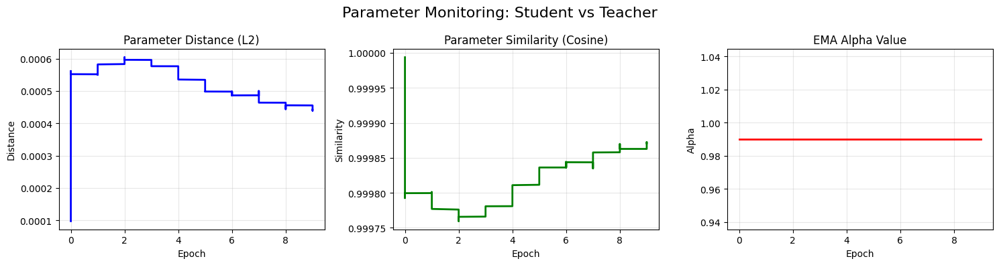


Epoch 11/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 15.01it/s]


Train Loss: 0.2833
Val Loss: 0.2555, Dice: 0.8670, IoU: 0.7908
Param Distance: 0.000451, Similarity: 0.999865
✓ Best model saved! Dice: 0.8670

Epoch 12/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 15.12it/s]


Train Loss: 0.2770
Val Loss: 0.2509, Dice: 0.8703, IoU: 0.7953
✓ Best model saved! Dice: 0.8703

Epoch 13/100
------------------------------


Validation: 100%|██████████| 25/25 [00:02<00:00, 11.58it/s]

Train Loss: 0.2670
Val Loss: 0.2466, Dice: 0.8700, IoU: 0.7960

Epoch 14/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.93it/s]

Train Loss: 0.2626
Val Loss: 0.2519, Dice: 0.8680, IoU: 0.7945

Epoch 15/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.93it/s]

Train Loss: 0.2554
Val Loss: 0.2496, Dice: 0.8692, IoU: 0.7955

Epoch 16/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 13.29it/s]

Train Loss: 0.2451
Val Loss: 0.2548, Dice: 0.8674, IoU: 0.7920
Param Distance: 0.000365, Similarity: 0.999911

Epoch 17/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.32it/s]

Train Loss: 0.2508
Val Loss: 0.2507, Dice: 0.8689, IoU: 0.7944

Epoch 18/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 15.01it/s]

Train Loss: 0.2375
Val Loss: 0.2496, Dice: 0.8701, IoU: 0.7970

Epoch 19/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.94it/s]

Train Loss: 0.2307
Val Loss: 0.2486, Dice: 0.8686, IoU: 0.7954

Epoch 20/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 10.95it/s]


Train Loss: 0.2239
Val Loss: 0.2537, Dice: 0.8654, IoU: 0.7913


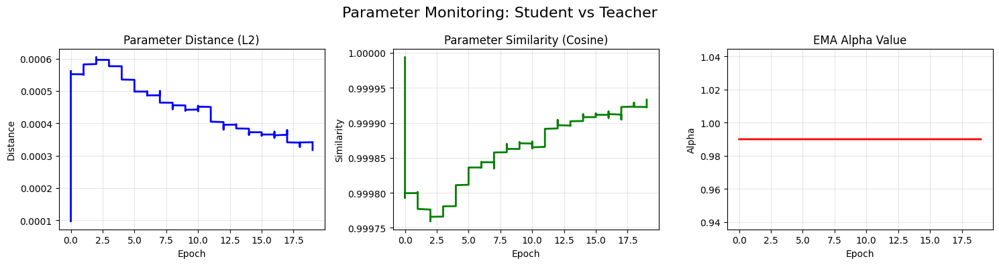


Epoch 21/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.89it/s]

Train Loss: 0.2257
Val Loss: 0.2587, Dice: 0.8702, IoU: 0.7976
Param Distance: 0.000311, Similarity: 0.999936

Epoch 22/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.87it/s]

Train Loss: 0.2277
Val Loss: 0.2556, Dice: 0.8691, IoU: 0.7961

Epoch 23/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.95it/s]


Train Loss: 0.2119
Val Loss: 0.2412, Dice: 0.8777, IoU: 0.8061
✓ Best model saved! Dice: 0.8777

Epoch 24/100
------------------------------


Validation: 100%|██████████| 25/25 [00:02<00:00, 10.75it/s]

Train Loss: 0.2040
Val Loss: 0.2533, Dice: 0.8653, IoU: 0.7935

Epoch 25/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.85it/s]

Train Loss: 0.1950
Val Loss: 0.2472, Dice: 0.8699, IoU: 0.7999

Epoch 26/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.83it/s]

Train Loss: 0.1933
Val Loss: 0.2563, Dice: 0.8674, IoU: 0.7937
Param Distance: 0.000259, Similarity: 0.999955

Epoch 27/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 11.33it/s]

Train Loss: 0.1902
Val Loss: 0.2483, Dice: 0.8645, IoU: 0.7918

Epoch 28/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.94it/s]

Train Loss: 0.1785
Val Loss: 0.2443, Dice: 0.8725, IoU: 0.8027

Epoch 29/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.68it/s]

Train Loss: 0.1766
Val Loss: 0.2563, Dice: 0.8650, IoU: 0.7893

Epoch 30/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.69it/s]


Train Loss: 0.1731
Val Loss: 0.2529, Dice: 0.8703, IoU: 0.7988


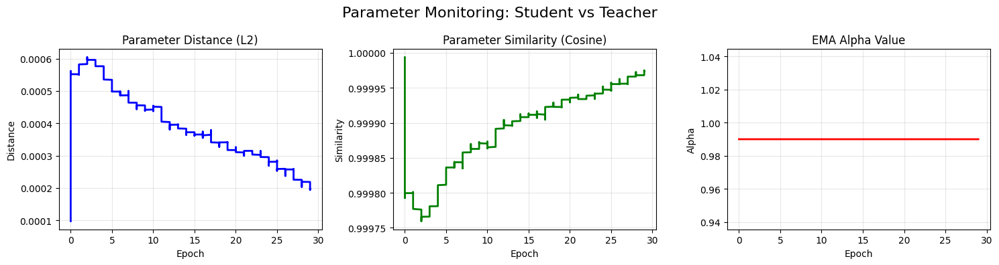


Epoch 31/100
------------------------------


Validation: 100%|██████████| 25/25 [00:02<00:00, 10.63it/s]

Train Loss: 0.1735
Val Loss: 0.2634, Dice: 0.8620, IoU: 0.7884
Param Distance: 0.000196, Similarity: 0.999974

Epoch 32/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.56it/s]

Train Loss: 0.1690
Val Loss: 0.2582, Dice: 0.8668, IoU: 0.7939

Epoch 33/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.42it/s]

Train Loss: 0.1681
Val Loss: 0.2567, Dice: 0.8666, IoU: 0.7954

Epoch 34/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 11.78it/s]

Train Loss: 0.1695
Val Loss: 0.2488, Dice: 0.8648, IoU: 0.7909

Epoch 35/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.67it/s]

Train Loss: 0.1690
Val Loss: 0.2449, Dice: 0.8682, IoU: 0.7967

Epoch 36/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.76it/s]

Train Loss: 0.1611
Val Loss: 0.2520, Dice: 0.8678, IoU: 0.7968
Param Distance: 0.000112, Similarity: 0.999992

Epoch 37/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.52it/s]

Train Loss: 0.1623
Val Loss: 0.2478, Dice: 0.8705, IoU: 0.7998

Epoch 38/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 13.53it/s]

Train Loss: 0.1654
Val Loss: 0.2528, Dice: 0.8690, IoU: 0.7981

Epoch 39/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.93it/s]

Train Loss: 0.1623
Val Loss: 0.2591, Dice: 0.8672, IoU: 0.7949

Epoch 40/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.60it/s]


Train Loss: 0.1621
Val Loss: 0.2562, Dice: 0.8650, IoU: 0.7939


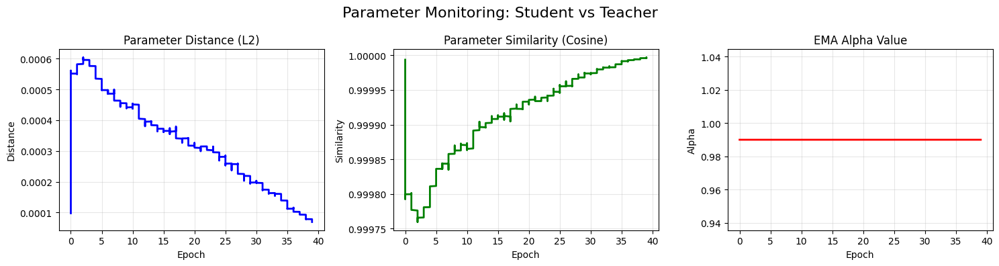


Epoch 41/100
------------------------------


Validation: 100%|██████████| 25/25 [00:02<00:00, 10.53it/s]

Train Loss: 0.1639
Val Loss: 0.2588, Dice: 0.8691, IoU: 0.7986
Param Distance: 0.000056, Similarity: 0.999998

Epoch 42/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.83it/s]

Train Loss: 0.1633
Val Loss: 0.2589, Dice: 0.8667, IoU: 0.7955

Epoch 43/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.67it/s]

Train Loss: 0.1561
Val Loss: 0.2564, Dice: 0.8671, IoU: 0.7965

Epoch 44/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 15.04it/s]

Train Loss: 0.1621
Val Loss: 0.2674, Dice: 0.8630, IoU: 0.7900

Epoch 45/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 13.05it/s]


Train Loss: 0.1579
Val Loss: 0.2699, Dice: 0.8624, IoU: 0.7886

Epoch 46/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.80it/s]

Train Loss: 0.1561
Val Loss: 0.2646, Dice: 0.8661, IoU: 0.7937
Param Distance: 0.000018, Similarity: 1.000000

Epoch 47/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.58it/s]

Train Loss: 0.1558
Val Loss: 0.2779, Dice: 0.8595, IoU: 0.7849

Epoch 48/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 10.58it/s]

Train Loss: 0.1531
Val Loss: 0.2675, Dice: 0.8629, IoU: 0.7894

Epoch 49/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.64it/s]

Train Loss: 0.1539
Val Loss: 0.2683, Dice: 0.8626, IoU: 0.7893

Epoch 50/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.96it/s]


Train Loss: 0.1537
Val Loss: 0.2699, Dice: 0.8639, IoU: 0.7915


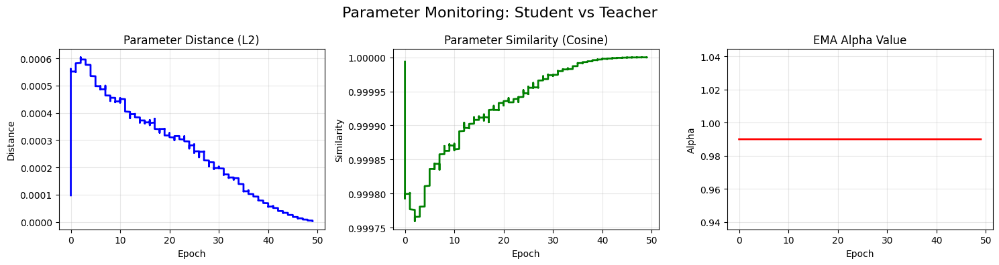


Epoch 51/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.76it/s]

Train Loss: 0.1543
Val Loss: 0.2645, Dice: 0.8650, IoU: 0.7922
Param Distance: 0.000001, Similarity: 1.000000

Epoch 52/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 10.67it/s]


Train Loss: 0.1554
Val Loss: 0.2683, Dice: 0.8636, IoU: 0.7905

Epoch 53/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.88it/s]

Train Loss: 0.1570
Val Loss: 0.2677, Dice: 0.8641, IoU: 0.7912

Epoch 54/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.87it/s]

Train Loss: 0.1575
Val Loss: 0.2670, Dice: 0.8646, IoU: 0.7917

Epoch 55/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 11.64it/s]

Train Loss: 0.1524
Val Loss: 0.2591, Dice: 0.8689, IoU: 0.7973

Epoch 56/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.69it/s]

Train Loss: 0.1569
Val Loss: 0.2597, Dice: 0.8682, IoU: 0.7969
Param Distance: 0.000014, Similarity: 1.000000

Epoch 57/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.59it/s]

Train Loss: 0.1568
Val Loss: 0.2684, Dice: 0.8642, IoU: 0.7911

Epoch 58/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.88it/s]

Train Loss: 0.1564
Val Loss: 0.2570, Dice: 0.8702, IoU: 0.7987

Epoch 59/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 11.23it/s]

Train Loss: 0.1566
Val Loss: 0.2717, Dice: 0.8608, IoU: 0.7870

Epoch 60/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.50it/s]


Train Loss: 0.1619
Val Loss: 0.2689, Dice: 0.8621, IoU: 0.7884


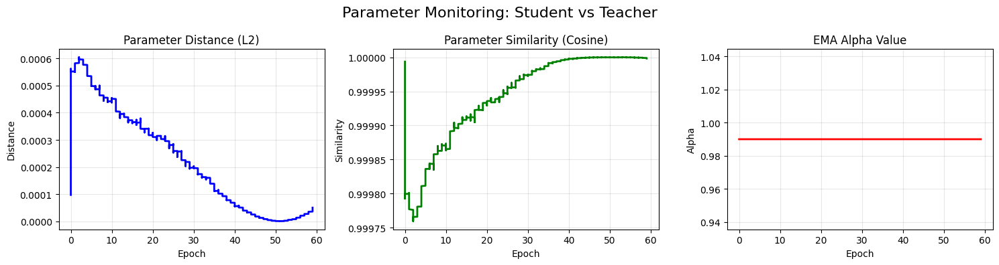


Epoch 61/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.79it/s]

Train Loss: 0.1566
Val Loss: 0.2789, Dice: 0.8590, IoU: 0.7847
Param Distance: 0.000056, Similarity: 0.999998

Epoch 62/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 13.40it/s]

Train Loss: 0.1542
Val Loss: 0.2611, Dice: 0.8673, IoU: 0.7951

Epoch 63/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 13.92it/s]

Train Loss: 0.1546
Val Loss: 0.2686, Dice: 0.8635, IoU: 0.7899

Epoch 64/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.70it/s]

Train Loss: 0.1537
Val Loss: 0.2646, Dice: 0.8643, IoU: 0.7906

Epoch 65/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.50it/s]

Train Loss: 0.1525
Val Loss: 0.2759, Dice: 0.8596, IoU: 0.7848

Epoch 66/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 11.22it/s]

Train Loss: 0.1489
Val Loss: 0.2748, Dice: 0.8617, IoU: 0.7884
Param Distance: 0.000115, Similarity: 0.999991

Epoch 67/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.97it/s]

Train Loss: 0.1509
Val Loss: 0.2806, Dice: 0.8585, IoU: 0.7831

Epoch 68/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.68it/s]

Train Loss: 0.1527
Val Loss: 0.2566, Dice: 0.8654, IoU: 0.7924

Epoch 69/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 10.57it/s]

Train Loss: 0.1562
Val Loss: 0.2726, Dice: 0.8601, IoU: 0.7855

Epoch 70/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.34it/s]


Train Loss: 0.1609
Val Loss: 0.2488, Dice: 0.8743, IoU: 0.8023


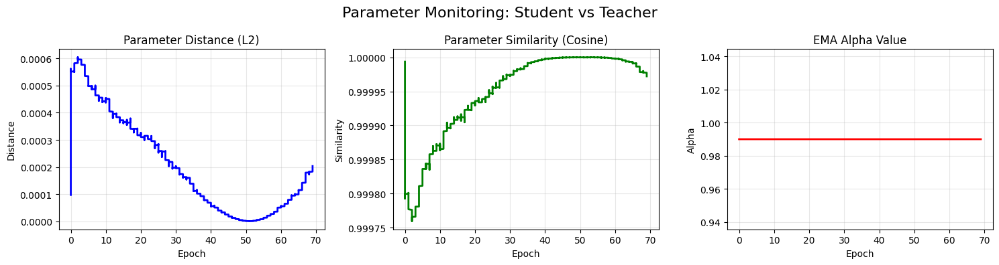


Epoch 71/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.56it/s]

Train Loss: 0.1594
Val Loss: 0.2619, Dice: 0.8669, IoU: 0.7944
Param Distance: 0.000229, Similarity: 0.999965

Epoch 72/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.64it/s]

Train Loss: 0.1631
Val Loss: 0.2485, Dice: 0.8749, IoU: 0.8022

Epoch 73/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 10.33it/s]

Train Loss: 0.1573
Val Loss: 0.2786, Dice: 0.8551, IoU: 0.7790

Epoch 74/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 13.60it/s]

Train Loss: 0.1637
Val Loss: 0.2610, Dice: 0.8650, IoU: 0.7926

Epoch 75/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.82it/s]

Train Loss: 0.1572
Val Loss: 0.2563, Dice: 0.8713, IoU: 0.7998

Epoch 76/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.38it/s]

Train Loss: 0.1584
Val Loss: 0.2586, Dice: 0.8707, IoU: 0.7982
Param Distance: 0.000297, Similarity: 0.999941

Epoch 77/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 12.79it/s]

Train Loss: 0.1593
Val Loss: 0.2628, Dice: 0.8614, IoU: 0.7867

Epoch 78/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.36it/s]

Train Loss: 0.1715
Val Loss: 0.2559, Dice: 0.8678, IoU: 0.7973

Epoch 79/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.43it/s]

Train Loss: 0.1690
Val Loss: 0.2484, Dice: 0.8760, IoU: 0.8035

Epoch 80/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 10.71it/s]


Train Loss: 0.1599
Val Loss: 0.2719, Dice: 0.8658, IoU: 0.7915


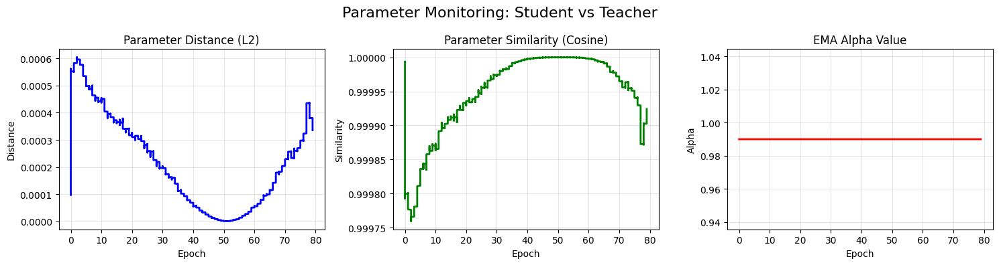


Epoch 81/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.49it/s]

Train Loss: 0.1643
Val Loss: 0.2563, Dice: 0.8713, IoU: 0.8012
Param Distance: 0.000377, Similarity: 0.999904

Epoch 82/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.60it/s]

Train Loss: 0.1630
Val Loss: 0.2752, Dice: 0.8594, IoU: 0.7875

Epoch 83/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.52it/s]

Train Loss: 0.1601
Val Loss: 0.2614, Dice: 0.8717, IoU: 0.7992

Epoch 84/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 10.66it/s]


Train Loss: 0.1583
Val Loss: 0.2437, Dice: 0.8805, IoU: 0.8117
✓ Best model saved! Dice: 0.8805

Epoch 85/100
------------------------------


Validation: 100%|██████████| 25/25 [00:01<00:00, 14.59it/s]

Train Loss: 0.1650
Val Loss: 0.2890, Dice: 0.8547, IoU: 0.7789

Epoch 86/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.39it/s]

Train Loss: 0.1666
Val Loss: 0.2775, Dice: 0.8602, IoU: 0.7852
Param Distance: 0.000545, Similarity: 0.999800

Epoch 87/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 11.77it/s]

Train Loss: 0.1705
Val Loss: 0.2684, Dice: 0.8641, IoU: 0.7916

Epoch 88/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.78it/s]

Train Loss: 0.1606
Val Loss: 0.2564, Dice: 0.8623, IoU: 0.7887

Epoch 89/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 13.93it/s]

Train Loss: 0.1530
Val Loss: 0.2650, Dice: 0.8692, IoU: 0.7982

Epoch 90/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.55it/s]


Train Loss: 0.1558
Val Loss: 0.2535, Dice: 0.8800, IoU: 0.8111


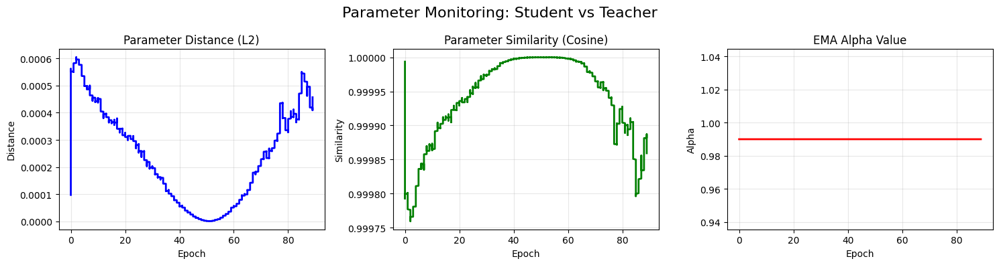


Epoch 91/100
------------------------------


Validation: 100%|██████████| 25/25 [00:02<00:00, 10.94it/s]

Train Loss: 0.1524
Val Loss: 0.2813, Dice: 0.8607, IoU: 0.7866
Param Distance: 0.000420, Similarity: 0.999881

Epoch 92/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.45it/s]

Train Loss: 0.1542
Val Loss: 0.2654, Dice: 0.8656, IoU: 0.7919

Epoch 93/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.60it/s]

Train Loss: 0.1607
Val Loss: 0.2640, Dice: 0.8685, IoU: 0.7946

Epoch 94/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 12.09it/s]

Train Loss: 0.1608
Val Loss: 0.2747, Dice: 0.8616, IoU: 0.7875

Epoch 95/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.26it/s]

Train Loss: 0.1635
Val Loss: 0.2715, Dice: 0.8599, IoU: 0.7857

Epoch 96/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.67it/s]

Train Loss: 0.1521
Val Loss: 0.2719, Dice: 0.8596, IoU: 0.7849
Param Distance: 0.000488, Similarity: 0.999839

Epoch 97/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.31it/s]

Train Loss: 0.1492
Val Loss: 0.2609, Dice: 0.8703, IoU: 0.7975

Epoch 98/100
------------------------------



Validation: 100%|██████████| 25/25 [00:02<00:00, 10.80it/s]

Train Loss: 0.1482
Val Loss: 0.2811, Dice: 0.8637, IoU: 0.7880

Epoch 99/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.61it/s]

Train Loss: 0.1666
Val Loss: 0.2881, Dice: 0.8525, IoU: 0.7731

Epoch 100/100
------------------------------



Validation: 100%|██████████| 25/25 [00:01<00:00, 14.65it/s]


Train Loss: 0.1638
Val Loss: 0.2850, Dice: 0.8550, IoU: 0.7772


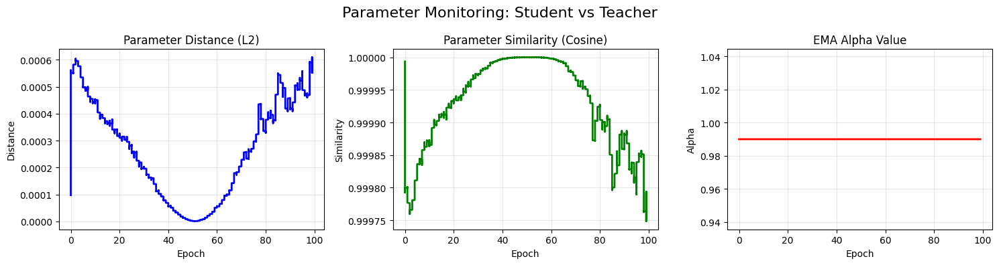


TRAINING COMPLETED
PARAMETER MONITORING SUMMARY
Total Epochs: 7000
Final Distance: 0.000552
Final Similarity: 0.999793
EMA Alpha: 0.9900
Distance Trend: ↓ Decreasing (-0.000000)


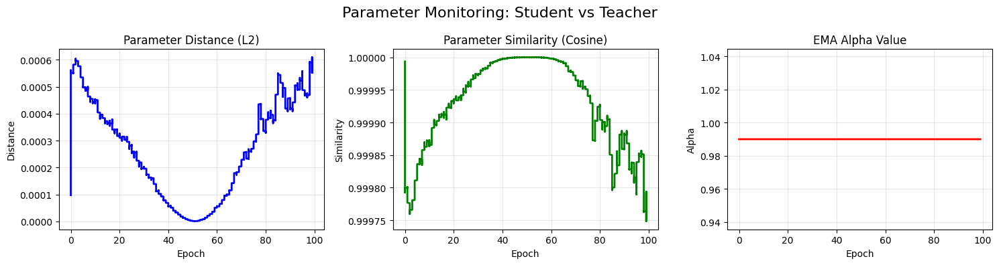

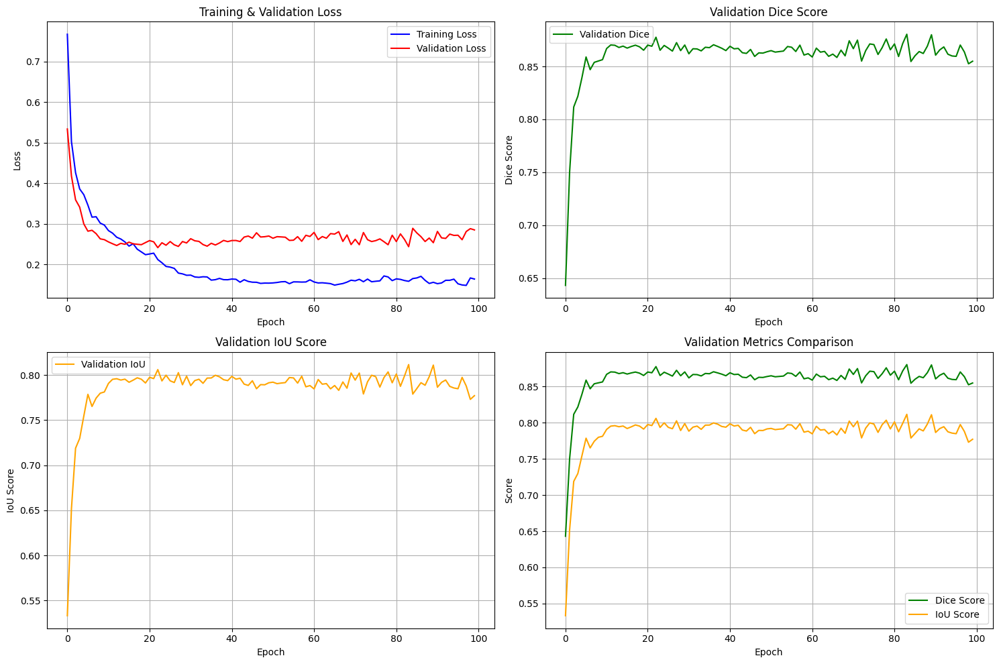


Training completed!
Best model saved as '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth'
Training history plot saved as 'training_history.png'


In [ ]:
# ===== MAIN TRAINING SCRIPT ====
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

    # Prepare data paths
base_path = "/content/Kvasir-SEG"
images_path = os.path.join(base_path, "images")
masks_path = os.path.join(base_path, "masks")

image_files = sorted([f for f in os.listdir(images_path) if f.endswith(('.jpg', '.jpeg', '.png'))])

image_paths = [os.path.join(images_path, f) for f in image_files]
mask_paths = [os.path.join(masks_path, f) for f in image_files]

    # Split data
train_images, val_images, train_masks, val_masks = train_test_split(
        image_paths, mask_paths, test_size=0.2, random_state=42
    )

    # Split training data into labeled (30%) and unlabeled (70%)
labeled_images, unlabeled_images, labeled_masks, _ = train_test_split(
        train_images, train_masks, test_size=0.7, random_state=42
    )

print(f"Labeled training samples: {len(labeled_images)}")
print(f"Unlabeled training samples: {len(unlabeled_images)}")
print(f"Validation samples: {len(val_images)}")

# Get transforms
train_transform, val_transform = get_transforms()

# Create datasets
labeled_dataset = KvasirDataset(labeled_images, labeled_masks, train_transform, is_labeled=True)
unlabeled_dataset = KvasirDataset(unlabeled_images, unlabeled_images, train_transform, is_labeled=False)  # No masks for unlabeled
val_dataset = KvasirDataset(val_images, val_masks, val_transform, is_labeled=True)

# Create data loaders
labeled_loader = DataLoader(labeled_dataset, batch_size=8, shuffle=True, num_workers=2)
unlabeled_loader = DataLoader(unlabeled_dataset, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

# Create models
student_model = create_model().to(device)
teacher_model = create_model().to(device)

# Loss function and optimizer
criterion = BALCLoss(mode='full')
optimizer = torch.optim.Adam(student_model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)

print("Starting training...")

history, monitor = train_semi_supervised(
    student_model, teacher_model,
    labeled_loader, unlabeled_loader, val_loader,
    criterion, optimizer, scheduler, device,
    num_epochs=100
    )

# Plot results
plot_training_history(history)

print("\nTraining completed!")
print("Best model saved as '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth'")
print("Training history plot saved as 'training_history.png'")

In [ ]:
def visualize_predictions(model_path, val_loader, device, num_samples=5):
    """Visualize model predictions"""
    model = create_model().to(device)
    model.load_state_dict(torch.load(model_path))
    model.eval()

    fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4*num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, -1)

    with torch.no_grad():
        for i, (images, masks) in enumerate(val_loader):
            if i >= num_samples:
                break

            images = images.to(device)
            outputs = model(images)
            predictions = torch.sigmoid(outputs) > 0.5

            # Take first image from batch
            image = images[0].cpu().numpy().transpose(1, 2, 0)
            mask = masks[0].cpu().numpy()
            pred = predictions[0].cpu().numpy()

            # Handle mask shape - remove channel dimension if exists
            if mask.ndim == 3 and mask.shape[0] == 1:
                mask = mask.squeeze(0)  # (1, H, W) -> (H, W)
            elif mask.ndim == 3 and mask.shape[-1] == 1:
                mask = mask.squeeze(-1)  # (H, W, 1) -> (H, W)

            # Handle prediction shape - remove channel dimension if exists
            if pred.ndim == 3 and pred.shape[0] == 1:
                pred = pred.squeeze(0)  # (1, H, W) -> (H, W)
            elif pred.ndim == 3 and pred.shape[-1] == 1:
                pred = pred.squeeze(-1)  # (H, W, 1) -> (H, W)

            # Denormalize image
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            image = std * image + mean
            image = np.clip(image, 0, 1)

            axes[i, 0].imshow(image)
            axes[i, 0].set_title('Original Image')
            axes[i, 0].axis('off')

            axes[i, 1].imshow(mask, cmap='gray')
            axes[i, 1].set_title('Ground Truth')
            axes[i, 1].axis('off')

            axes[i, 2].imshow(pred, cmap='gray')
            axes[i, 2].set_title('Prediction')
            axes[i, 2].axis('off')

    plt.tight_layout()
    plt.savefig('predictions_visualization.png', dpi=300, bbox_inches='tight')
    plt.show()


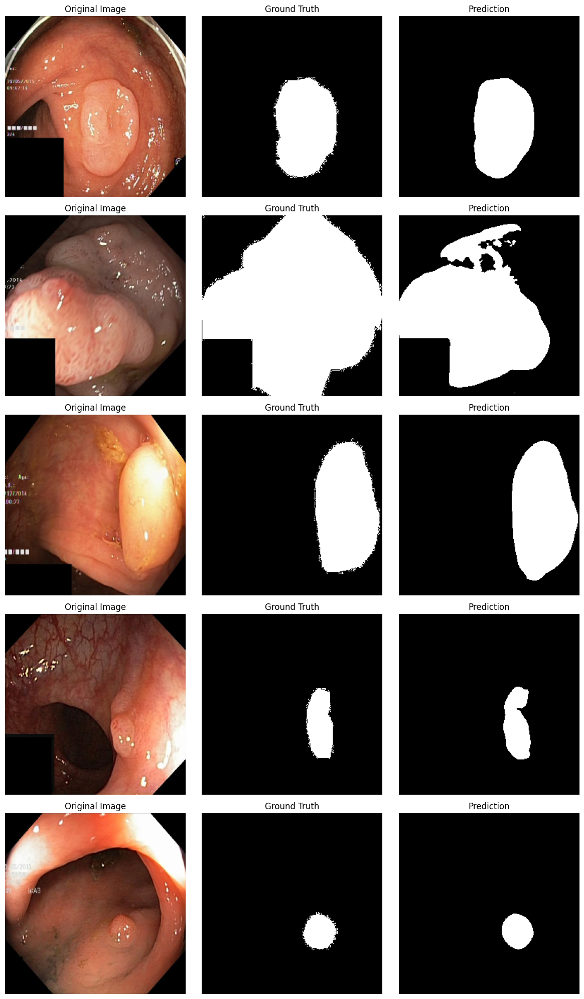

In [ ]:
base_path = "/content/Kvasir-SEG"
images_path = os.path.join(base_path, "images")
masks_path = os.path.join(base_path, "masks")
image_files = sorted([f for f in os.listdir(images_path) if f.endswith(('.jpg', '.jpeg', '.png'))])

image_paths = [os.path.join(images_path, f) for f in image_files]
mask_paths = [os.path.join(masks_path, f) for f in image_files]

train_images, val_images, train_masks, val_masks = train_test_split(
        image_paths, mask_paths, test_size=0.2, random_state=42
    )
train_transform, val_transform = get_transforms()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
val_dataset = KvasirDataset(val_images, val_masks, val_transform, is_labeled=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

visualize_predictions('/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth', val_loader, device)


In [ ]:
from skimage import measure
def visualize_predictions_with_contours(model_path, val_loader, device, num_samples=5):
    """Visualize model predictions with colored contours - Green for Ground Truth, Red for Predictions"""
    model = create_model().to(device)
    model.load_state_dict(torch.load(model_path))
    model.eval()

    fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4*num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, -1)

    with torch.no_grad():
        for i, (images, masks) in enumerate(val_loader):
            if i >= num_samples:
                break

            images = images.to(device)
            outputs = model(images)
            predictions = torch.sigmoid(outputs) > 0.5

            # Take first image from batch
            image = images[0].cpu().numpy().transpose(1, 2, 0)
            mask = masks[0].cpu().numpy()
            pred = predictions[0].cpu().numpy()

            # Handle mask shape - remove channel dimension if exists
            if mask.ndim == 3 and mask.shape[0] == 1:
                mask = mask.squeeze(0)  # (1, H, W) -> (H, W)
            elif mask.ndim == 3 and mask.shape[-1] == 1:
                mask = mask.squeeze(-1)  # (H, W, 1) -> (H, W)

            # Handle prediction shape - remove channel dimension if exists
            if pred.ndim == 3 and pred.shape[0] == 1:
                pred = pred.squeeze(0)  # (1, H, W) -> (H, W)
            elif pred.ndim == 3 and pred.shape[-1] == 1:
                pred = pred.squeeze(-1)  # (H, W, 1) -> (H, W)

            # Denormalize image
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            image = std * image + mean
            image = np.clip(image, 0, 1)

            # Create overlay image with contours
            overlay_image = image.copy()

            # Find contours for ground truth (green)
            mask_uint8 = (mask * 255).astype(np.uint8)
            gt_contours = measure.find_contours(mask_uint8, 128)

            # Find contours for predictions (red)
            pred_uint8 = (pred * 255).astype(np.uint8)
            pred_contours = measure.find_contours(pred_uint8, 128)

            # Plot original image
            axes[i, 0].imshow(image)
            axes[i, 0].set_title('Original Image')
            axes[i, 0].axis('off')

            # Plot ground truth
            axes[i, 1].imshow(mask, cmap='gray')
            axes[i, 1].set_title('Ground Truth')
            axes[i, 1].axis('off')
            # Plot prediction
            axes[i, 2].imshow(pred, cmap='gray')
            axes[i, 2].set_title('Prediction')
            axes[i, 2].axis('off')

            # Plot overlay with contours
            axes[i, 3].imshow(overlay_image)

            # Draw ground truth contours in green
            for contour in gt_contours:
                axes[i, 3].plot(contour[:, 1], contour[:, 0], color='green', linewidth=2, label='Ground Truth')

            # Draw prediction contours in red
            for contour in pred_contours:
                axes[i, 3].plot(contour[:, 1], contour[:, 0], color='red', linewidth=2, label='Prediction')

            axes[i, 3].set_title('Overlay (Green: GT, Red: Pred)')
            axes[i, 3].axis('off')

            # Add legend only for the first sample to avoid cluttering
            if i == 0:
                axes[i, 3].legend(loc='upper right', bbox_to_anchor=(1, 1))

    plt.tight_layout()
    plt.savefig('predictions_with_contours.png', dpi=300, bbox_inches='tight')
    plt.show()


def predict_single_image(model_path, image_path, device, visualize=True):
    """Predict segmentation for a single image from path"""
    # Load model
    model = create_model().to(device)
    model.load_state_dict(torch.load(model_path))
    model.eval()

    # Define transforms (should match your training transforms)
    transform = transforms.Compose([
        transforms.Resize((224, 224)),  # Adjust size based on your model
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    # Load and preprocess image
    image = Image.open(image_path).convert('RGB')
    original_size = image.size

    # Apply transforms
    input_tensor = transform(image).unsqueeze(0).to(device)

    # Make prediction
    with torch.no_grad():
        output = model(input_tensor)
        prediction = torch.sigmoid(output) > 0.5
        prediction_prob = torch.sigmoid(output)

    # Convert to numpy
    pred_mask = prediction[0].cpu().numpy()
    pred_prob = prediction_prob[0].cpu().numpy()

    # Handle prediction shape
    if pred_mask.ndim == 3 and pred_mask.shape[0] == 1:
        pred_mask = pred_mask.squeeze(0)
    if pred_prob.ndim == 3 and pred_prob.shape[0] == 1:
        pred_prob = pred_prob.squeeze(0)

    # Resize prediction back to original image size
    pred_mask_resized = cv2.resize(pred_mask.astype(np.uint8), original_size, interpolation=cv2.INTER_NEAREST)
    pred_prob_resized = cv2.resize(pred_prob, original_size, interpolation=cv2.INTER_LINEAR)

    if visualize:
        # Create visualization
        fig, axes = plt.subplots(1, 4, figsize=(16, 4))

        # Original image
        axes[0].imshow(image)
        axes[0].set_title('Original Image')
        axes[0].axis('off')

        # Binary prediction
        axes[1].imshow(pred_mask_resized, cmap='gray')
        axes[1].set_title('Binary Prediction')
        axes[1].axis('off')

        # Probability map
        axes[2].imshow(pred_prob_resized, cmap='hot', vmin=0, vmax=1)
        axes[2].set_title('Probability Map')
        axes[2].axis('off')

        # Overlay
        overlay = np.array(image)

        # Find contours for prediction
        pred_contours = measure.find_contours(pred_mask_resized * 255, 128)

        axes[3].imshow(overlay)
        for contour in pred_contours:
            axes[3].plot(contour[:, 1], contour[:, 0], color='red', linewidth=2)
        axes[3].set_title('Prediction Overlay')
        axes[3].axis('off')

        plt.tight_layout()
        plt.savefig(f'single_prediction_{image_path.split("/")[-1]}', dpi=300, bbox_inches='tight')
        plt.show()

    return pred_mask_resized, pred_prob_resized


def predict_single_image_with_ground_truth(model_path, image_path, mask_path, device):
    """Predict and compare with ground truth for a single image"""
    # Load model
    model = create_model().to(device)
    model.load_state_dict(torch.load(model_path))
    model.eval()

    # Define transforms
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    # Load image and mask
    image = Image.open(image_path).convert('RGB')
    mask = Image.open(mask_path).convert('L')  # Convert to grayscale
    original_size = image.size

    # Apply transforms
    input_tensor = transform(image).unsqueeze(0).to(device)

    # Make prediction
    with torch.no_grad():
        output = model(input_tensor)
        prediction = torch.sigmoid(output) > 0.5

    # Convert to numpy
    pred_mask = prediction[0].cpu().numpy()
    if pred_mask.ndim == 3 and pred_mask.shape[0] == 1:
        pred_mask = pred_mask.squeeze(0)

    # Resize prediction back to original size
    pred_mask_resized = cv2.resize(pred_mask.astype(np.uint8), original_size, interpolation=cv2.INTER_NEAREST)

    # Process ground truth mask
    mask_array = np.array(mask)
    if mask_array.max() > 1:
        mask_array = mask_array / 255.0  # Normalize to 0-1

    # Create visualization
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    # Original image
    axes[0].imshow(image)
    axes[0].set_title('Original Image', fontsize=14)
    axes[0].axis('off')

    # Ground truth
    axes[1].imshow(mask_array, cmap='gray')
    axes[1].set_title('Ground Truth', fontsize=14)
    axes[1].axis('off')

    # Prediction
    axes[2].imshow(pred_mask_resized, cmap='gray')
    axes[2].set_title('Prediction', fontsize=14)
    axes[2].axis('off')

    # Overlay with contours
    overlay = np.array(image)
    axes[3].imshow(overlay)

    # Find and draw contours
    # Ground truth contours (green)
    gt_contours = measure.find_contours(mask_array * 255, 128)
    for contour in gt_contours:
        axes[3].plot(contour[:, 1], contour[:, 0], color='green', linewidth=3, label='Ground Truth')

    # Prediction contours (red)
    pred_contours = measure.find_contours(pred_mask_resized * 255, 128)
    for contour in pred_contours:
        axes[3].plot(contour[:, 1], contour[:, 0], color='red', linewidth=2, label='Prediction')

    axes[3].set_title('Comparison\n(Green: GT, Red: Pred)', fontsize=14)
    axes[3].axis('off')

    # Calculate metrics
    intersection = np.logical_and(mask_array > 0.5, pred_mask_resized > 0.5)
    union = np.logical_or(mask_array > 0.5, pred_mask_resized > 0.5)
    iou = np.sum(intersection) / np.sum(union) if np.sum(union) > 0 else 0

    dice = 2 * np.sum(intersection) / (np.sum(mask_array > 0.5) + np.sum(pred_mask_resized > 0.5))

    plt.suptitle(f'IoU: {iou:.4f}, Dice: {dice:.4f}', fontsize=16, y=1.02)
    plt.tight_layout()
    plt.savefig(f'comparison_{image_path.split("/")[-1]}', dpi=300, bbox_inches='tight')
    plt.show()

    return pred_mask_resized, iou, dice


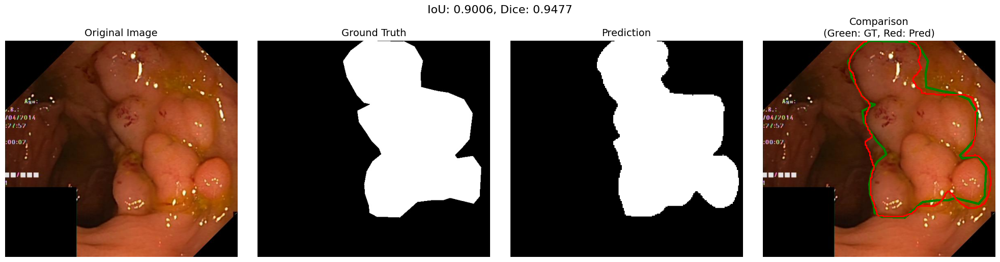

In [ ]:
pred_mask, iou, dice = predict_single_image_with_ground_truth(
    '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth',
    '/content/Kvasir-SEG/images/cju6xlygpw7bs0818n691jsq4.jpg',
    '/content/Kvasir-SEG/masks/cju6xlygpw7bs0818n691jsq4.jpg',
    device
)

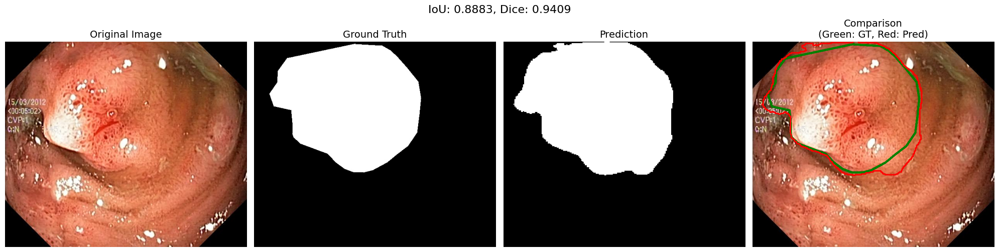

In [ ]:
pred_mask, iou, dice = predict_single_image_with_ground_truth(
    '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth',
    '/content/Kvasir-SEG/images/cju0qkwl35piu0993l0dewei2.jpg',
    '/content/Kvasir-SEG/masks/cju0qkwl35piu0993l0dewei2.jpg',
    device
)

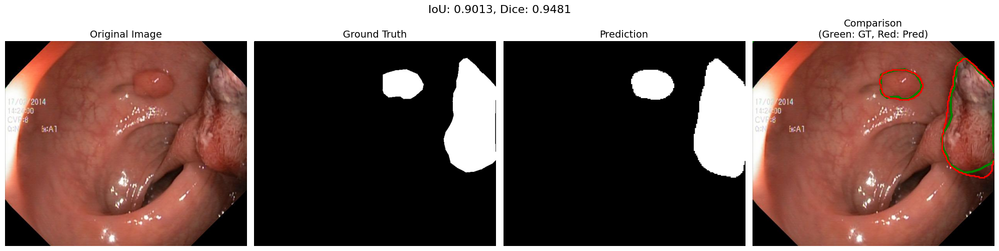

In [ ]:
pred_mask, iou, dice = predict_single_image_with_ground_truth(
    '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth',
    '/content/Kvasir-SEG/images/cju0roawvklrq0799vmjorwfv.jpg',
    '/content/Kvasir-SEG/masks/cju0roawvklrq0799vmjorwfv.jpg',
    device
)

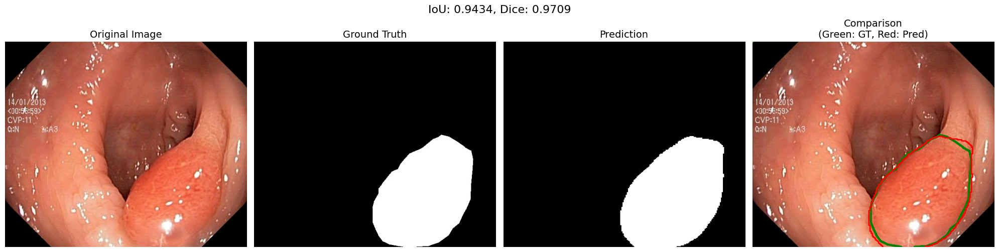

In [ ]:
pred_mask, iou, dice = predict_single_image_with_ground_truth(
    '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth',
    '/content/Kvasir-SEG/images/cju15wdt3zla10801odjiw7sy.jpg',
    '/content/Kvasir-SEG/masks/cju15wdt3zla10801odjiw7sy.jpg',
    device
)

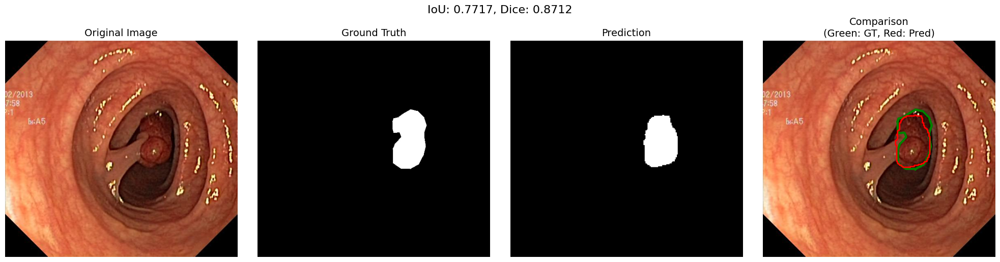

In [ ]:
pred_mask, iou, dice = predict_single_image_with_ground_truth(
    '/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth',
    '/content/Kvasir-SEG/images/cju1ddr6p4k5z08780uuuzit2.jpg',
    '/content/Kvasir-SEG/masks/cju1ddr6p4k5z08780uuuzit2.jpg',
    device
)

In [ ]:
def dice_coefficient_single(pred, target, smooth=1e-6):
    """Calculate dice coefficient for a single image"""
    pred = torch.sigmoid(pred) if pred.dtype == torch.float32 else pred
    pred = (pred > 0.5).float()

    # Ensure same shape
    if target.dim() != pred.dim():
        if target.dim() == 2:  # [H, W] -> [1, H, W]
            target = target.unsqueeze(0)
        elif pred.dim() == 2:  # [H, W] -> [1, H, W]
            pred = pred.unsqueeze(0)

    intersection = (pred * target).sum()
    dice = (2 * intersection + smooth) / (pred.sum() + target.sum() + smooth)
    return dice.item()

def visualize_predictions(model_path, val_loader, device, num_samples=5):
    """Visualize model predictions with dice scores"""
    model = create_model().to(device)
    model.load_state_dict(torch.load(model_path))
    model.eval()

    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 4*num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, -1)

    dice_scores = []

    with torch.no_grad():
        for i, (images, masks) in enumerate(val_loader):
            if i >= num_samples:
                break

            images = images.to(device)
            outputs = model(images)
            predictions = torch.sigmoid(outputs) > 0.5

            # Take first image from batch
            image = images[0].cpu().numpy().transpose(1, 2, 0)
            mask = masks[0].cpu().numpy()
            pred = predictions[0].cpu().numpy()

            # Handle mask shape - remove channel dimension if exists
            if mask.ndim == 3 and mask.shape[0] == 1:
                mask = mask.squeeze(0)  # (1, H, W) -> (H, W)
            elif mask.ndim == 3 and mask.shape[-1] == 1:
                mask = mask.squeeze(-1)  # (H, W, 1) -> (H, W)

            # Handle prediction shape - remove channel dimension if exists
            if pred.ndim == 3 and pred.shape[0] == 1:
                pred = pred.squeeze(0)  # (1, H, W) -> (H, W)
            elif pred.ndim == 3 and pred.shape[-1] == 1:
                pred = pred.squeeze(-1)  # (H, W, 1) -> (H, W)

            # Calculate dice score for this image
            dice_score = dice_coefficient_single(
                torch.tensor(pred).float(),
                torch.tensor(mask).float()
            )
            dice_scores.append(dice_score)

            # Denormalize image
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            image = std * image + mean
            image = np.clip(image, 0, 1)

            # Plot original image
            axes[i, 0].imshow(image)
            axes[i, 0].set_title('Original Image')
            axes[i, 0].axis('off')

            # Plot ground truth
            axes[i, 1].imshow(mask, cmap='gray')
            axes[i, 1].set_title('Ground Truth')
            axes[i, 1].axis('off')

            # Plot prediction with dice score
            axes[i, 2].imshow(pred, cmap='gray')
            axes[i, 2].set_title(f'Prediction\nDice: {dice_score:.4f}')
            axes[i, 2].axis('off')

    # Add overall statistics
    avg_dice = np.mean(dice_scores)
    std_dice = np.std(dice_scores)

    plt.suptitle(f'Prediction Results\nAverage Dice: {avg_dice:.4f} ± {std_dice:.4f}',
                 fontsize=16, y=0.98)

    plt.tight_layout()
    plt.subplots_adjust(top=0.93)  # Make room for suptitle
    plt.savefig('predictions_visualization.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Print detailed statistics
    print("\n" + "="*50)
    print("PREDICTION STATISTICS")
    print("="*50)
    for i, dice in enumerate(dice_scores):
        print(f"Image {i+1}: Dice = {dice:.4f}")
    print("-"*50)
    print(f"Average Dice: {avg_dice:.4f}")
    print(f"Standard Deviation: {std_dice:.4f}")
    print(f"Min Dice: {min(dice_scores):.4f}")
    print(f"Max Dice: {max(dice_scores):.4f}")
    print("="*50)

    return dice_scores

# Alternative version with more detailed visualization
def visualize_predictions_detailed(model_path, val_loader, device, num_samples=5):
    """Enhanced visualization with overlay and detailed metrics"""
    model = create_model().to(device)
    model.load_state_dict(torch.load(model_path))
    model.eval()

    fig, axes = plt.subplots(num_samples, 4, figsize=(20, 4*num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, -1)

    dice_scores = []

    with torch.no_grad():
        for i, (images, masks) in enumerate(val_loader):
            if i >= num_samples:
                break

            images = images.to(device)
            outputs = model(images)
            predictions = torch.sigmoid(outputs) > 0.5

            # Take first image from batch
            image = images[0].cpu().numpy().transpose(1, 2, 0)
            mask = masks[0].cpu().numpy()
            pred = predictions[0].cpu().numpy()

            # Handle shapes
            if mask.ndim == 3 and mask.shape[0] == 1:
                mask = mask.squeeze(0)
            elif mask.ndim == 3 and mask.shape[-1] == 1:
                mask = mask.squeeze(-1)

            if pred.ndim == 3 and pred.shape[0] == 1:
                pred = pred.squeeze(0)
            elif pred.ndim == 3 and pred.shape[-1] == 1:
                pred = pred.squeeze(-1)

            # Calculate dice score
            dice_score = dice_coefficient_single(
                torch.tensor(pred).float(),
                torch.tensor(mask).float()
            )
            dice_scores.append(dice_score)

            # Denormalize image
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            image = std * image + mean
            image = np.clip(image, 0, 1)

            # Create overlay
            overlay = image.copy()
            overlay[:,:,0] = np.where(mask == 1, 1.0, overlay[:,:,0])  # Red for GT
            overlay[:,:,1] = np.where(pred == 1, 1.0, overlay[:,:,1])  # Green for pred

            # Plot all versions
            axes[i, 0].imshow(image)
            axes[i, 0].set_title('Original Image')
            axes[i, 0].axis('off')

            axes[i, 1].imshow(mask, cmap='gray')
            axes[i, 1].set_title('Ground Truth')
            axes[i, 1].axis('off')

            axes[i, 2].imshow(pred, cmap='gray')
            axes[i, 2].set_title(f'Prediction\nDice: {dice_score:.4f}')
            axes[i, 2].axis('off')

            axes[i, 3].imshow(overlay)
            axes[i, 3].set_title('Overlay\n(Red: GT, Green: Pred)')
            axes[i, 3].axis('off')

    # Add overall statistics
    avg_dice = np.mean(dice_scores)
    std_dice = np.std(dice_scores)

    plt.suptitle(f'Detailed Prediction Results\nAverage Dice: {avg_dice:.4f} ± {std_dice:.4f}',
                 fontsize=16, y=0.98)

    plt.tight_layout()
    plt.subplots_adjust(top=0.93)
    plt.savefig('predictions_detailed_visualization.png', dpi=300, bbox_inches='tight')
    plt.show()

    return dice_scores

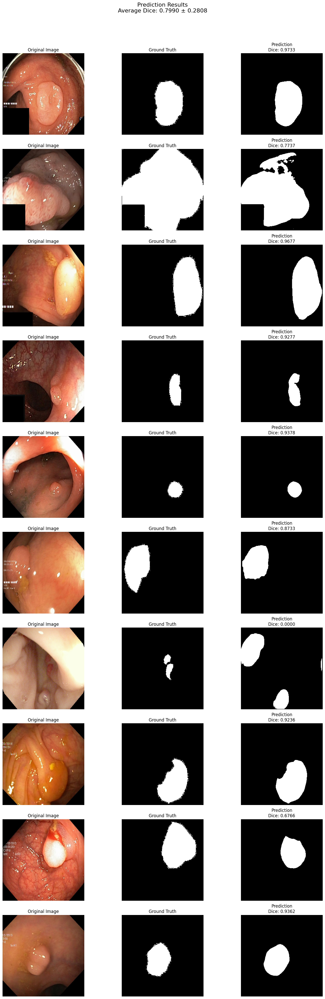


PREDICTION STATISTICS
Image 1: Dice = 0.9733
Image 2: Dice = 0.7737
Image 3: Dice = 0.9677
Image 4: Dice = 0.9277
Image 5: Dice = 0.9378
Image 6: Dice = 0.8733
Image 7: Dice = 0.0000
Image 8: Dice = 0.9236
Image 9: Dice = 0.6766
Image 10: Dice = 0.9362
--------------------------------------------------
Average Dice: 0.7990
Standard Deviation: 0.2808
Min Dice: 0.0000
Max Dice: 0.9733


In [ ]:
dice_scores = visualize_predictions('/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth', val_loader, device, num_samples=10)

In [ ]:
print(np.max(history['val_dice']))
print(np.max(history['val_iou']))

0.8804750251770019
0.8116712641716003


In [ ]:
from skimage import measure

def visualize_worst_predictions_with_contours(model_path, val_loader, device, worst_k=5):

    model = create_model().to(device)
    model.load_state_dict(torch.load(model_path))
    model.eval()

    results = []

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            outputs = model(images)
            preds = torch.sigmoid(outputs) > 0.5

            batch_size = images.shape[0]

            for b in range(batch_size):

                pred = preds[b].cpu()
                mask = masks[b].cpu()

                dice = dice_coefficient_single(pred.float(), mask.float())

                results.append({
                    "dice": dice,
                    "image": images[b].cpu(),
                    "mask": mask,
                    "pred": pred
                })

    # sort theo dice tăng dần (worst first)
    results = sorted(results, key=lambda x: x["dice"])
    worst_samples = results[:worst_k]

    fig, axes = plt.subplots(worst_k, 4, figsize=(16, 4 * worst_k))

    if worst_k == 1:
        axes = axes.reshape(1, -1)

    for i, sample in enumerate(worst_samples):

        image = sample["image"].numpy().transpose(1,2,0)
        mask = sample["mask"].numpy()
        pred = sample["pred"].numpy()
        dice = sample["dice"]

        # remove channel dim
        if mask.ndim == 3 and mask.shape[0] == 1:
            mask = mask.squeeze(0)

        if pred.ndim == 3 and pred.shape[0] == 1:
            pred = pred.squeeze(0)

        # denormalize
        mean = np.array([0.485,0.456,0.406])
        std = np.array([0.229,0.224,0.225])

        image = std * image + mean
        image = np.clip(image,0,1)

        # find contours
        mask_uint8 = (mask * 255).astype(np.uint8)
        pred_uint8 = (pred * 255).astype(np.uint8)

        gt_contours = measure.find_contours(mask_uint8, 128)
        pred_contours = measure.find_contours(pred_uint8, 128)

        # ORIGINAL
        axes[i,0].imshow(image)
        axes[i,0].set_title("Image")
        axes[i,0].axis("off")

        # GT
        axes[i,1].imshow(mask, cmap="gray")
        axes[i,1].set_title("Ground Truth")
        axes[i,1].axis("off")

        # PRED
        axes[i,2].imshow(pred, cmap="gray")
        axes[i,2].set_title(f"Prediction\nDice={dice:.4f}")
        axes[i,2].axis("off")

        # OVERLAY
        axes[i,3].imshow(image)

        for contour in gt_contours:
            axes[i,3].plot(contour[:,1], contour[:,0], color="green", linewidth=2)

        for contour in pred_contours:
            axes[i,3].plot(contour[:,1], contour[:,0], color="red", linewidth=2)

        axes[i,3].set_title("Contours\n(Green=GT, Red=Pred)")
        axes[i,3].axis("off")

    plt.tight_layout()
    plt.savefig("worst_predictions_contours.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("\nWorst Dice scores:")
    for i, sample in enumerate(worst_samples):
        print(f"{i+1}. Dice = {sample['dice']:.4f}")

    return worst_samples

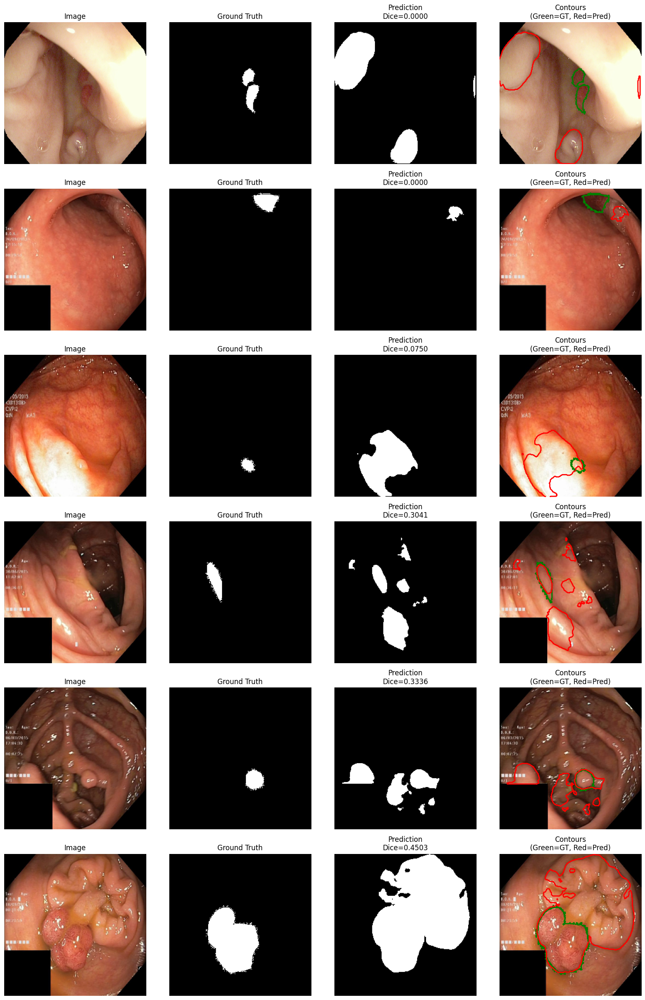


Worst Dice scores:
1. Dice = 0.0000
2. Dice = 0.0000
3. Dice = 0.0750
4. Dice = 0.3041
5. Dice = 0.3336
6. Dice = 0.4503


[{'dice': 1.103509159050553e-10,
  'image': tensor([[[-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           ...,
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179]],
  
          [[-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           ...,
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357]],
  
          [[-1.8044, -1.8044, -1.8044,  ..

In [ ]:
visualize_worst_predictions_with_contours('/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth', val_loader, device, worst_k=6)





Worst Dice scores:
1. Dice = 0.0000
2. Dice = 0.0000
3. Dice = 0.0750
4. Dice = 0.3041
5. Dice = 0.3336
6. Dice = 0.4503
7. Dice = 0.4926
8. Dice = 0.5037
9. Dice = 0.5363
10. Dice = 0.5860
11. Dice = 0.6570
12. Dice = 0.6591
13. Dice = 0.6617
14. Dice = 0.6633
15. Dice = 0.6766
16. Dice = 0.6766
17. Dice = 0.6776
18. Dice = 0.6778
19. Dice = 0.6782
20. Dice = 0.6818
21. Dice = 0.7160
22. Dice = 0.7162
23. Dice = 0.7257
24. Dice = 0.7261
25. Dice = 0.7421
26. Dice = 0.7623
27. Dice = 0.7737
28. Dice = 0.7737
29. Dice = 0.7848
30. Dice = 0.7885


[{'dice': 1.103509159050553e-10,
  'image': tensor([[[-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           ...,
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179]],
  
          [[-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           ...,
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357]],
  
          [[-1.8044, -1.8044, -1.8044,  ..

In [ ]:
visualize_worst_predictions_with_contours('/content/drive/MyDrive/ACMI/Đề tài Thạc sĩ 2025/BALC/Ablation Study/full/best_model.pth', val_loader, device, worst_k=30)